In [10]:
import joblib

x_train_scaled=joblib.load( '../models/data/x_train_scaled.pkl')
x_test_scaled=joblib.load('../models/data/x_test_scaled.pkl')

y_train = joblib.load('../models/data/y_train.pkl')
y_test = joblib.load('../models/data/y_test.pkl')

In [11]:
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost': XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        objective='multi:softprob',
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=-1
    ),
     'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'SVM': SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),
}

In [12]:
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
import pandas as pd



cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('model', clone(model))
    ])

    scores = cross_validate(
        pipeline,
        x_train_scaled,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-score': scores['test_f1'].mean()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-score',
    ascending=False
)

print(results_df.round(3))

/home/yassine/Projets/brief-croiser/PsychoTrack/.env/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yassine/Projets/brief-croiser/PsychoTrack/.env/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yassine/Projets/brief-croiser/PsychoTrack/.env/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yassine/Projets/brief-croiser/PsychoTrack/.env/lib/p

                 Model  Accuracy  Precision  Recall  F1-score
0  Logistic Regression     0.752      0.752   0.751     0.751
4                  SVM     0.725      0.728   0.725     0.725
2              XGBoost     0.694      0.690   0.693     0.691
1        Random Forest     0.670      0.664   0.669     0.665
5                  KNN     0.594      0.611   0.595     0.595
3        Decision Tree     0.561      0.562   0.560     0.561


In [13]:
final_model = LogisticRegression(max_iter=1000)

final_model.fit(x_train_scaled, y_train)

y_pred = final_model.predict(x_test_scaled)

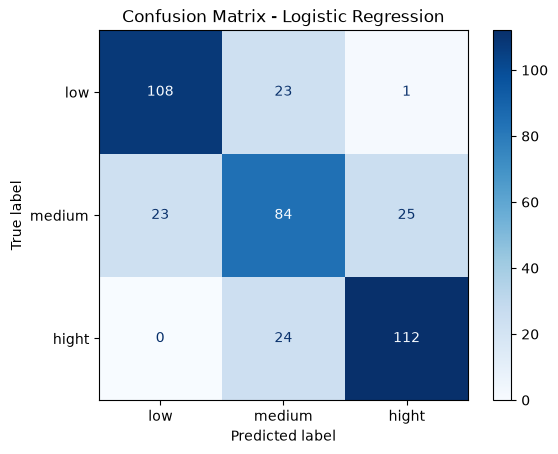

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0,1,2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['low','medium','hight']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy :", accuracy_score(y_test, y_pred))

print("Precision :", precision_score(y_test, y_pred, average='macro'))

print("Recall :", recall_score(y_test, y_pred, average='macro'))

print("F1-score :", f1_score(y_test, y_pred, average='macro'))

Accuracy : 0.76
Precision : 0.7590810192867942
Recall : 0.7593582887700535
F1-score : 0.7591980979341862


In [16]:
from sklearn.metrics import roc_auc_score

y_proba = final_model.predict_proba(x_test_scaled)

auc = roc_auc_score(
    y_test,
    y_proba,
    multi_class='ovr',
    average='macro'
)

print("ROC-AUC :", auc)

ROC-AUC : 0.9141120378499658


In [17]:
models_params = {

    'Logistic Regression': {
        'model': LogisticRegression(max_iter=2000),
        'params': {
            'model__C': [0.01, 0.1, 1, 10, 100],
            'model__solver': ['lbfgs'],
            'model__class_weight': [None, 'balanced']
        }
    },

    'SVM': {
        'model': SVC(),
        'params': [
            {
                'model__kernel': ['linear'],
                'model__C': [0.1, 1, 10, 100]
            },
            {
                'model__kernel': ['rbf'],
                'model__C': [0.1, 1, 10, 100],
                'model__gamma': ['scale', 'auto']
            }
        ]
    },
    
    'XGBoost': {
        'model': XGBClassifier(
            objective='multi:softprob',
            eval_metric='mlogloss',
            random_state=42,
            n_jobs=1
        ),
        'params': {
            'model__n_estimators': [100, 200, 300],
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__max_depth': [3, 5, 7],
            'model__subsample': [0.8, 1.0]
        }
    }
}

In [18]:
from sklearn.model_selection import GridSearchCV
results = []
best_models = {}

for name, config in models_params.items():

    print(f"\nOptimisation de : {name}")

    pipeline = Pipeline([
        ('model', config['model'])
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=config['params'],
        cv=cv,
        scoring='f1_macro',
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    grid.fit(x_train_scaled, y_train)

    best_models[name] = grid.best_estimator_

    results.append({
        'Model': name,
        'Best F1-score': grid.best_score_,
        'Best Parameters': grid.best_params_
    })

    print("Meilleur F1-score :", round(grid.best_score_, 4))
    print("Meilleurs paramètres :", grid.best_params_)


Optimisation de : Logistic Regression
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Meilleur F1-score : 0.7536
Meilleurs paramètres : {'model__C': 10, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}

Optimisation de : SVM
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleur F1-score : 0.7467
Meilleurs paramètres : {'model__C': 0.1, 'model__kernel': 'linear'}

Optimisation de : XGBoost
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Meilleur F1-score : 0.7026
Meilleurs paramètres : {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}
